# COMP 5360 Final Project 
# Title: Exploring Formula 1 in the Ground Effect Era

Preface: This was originally a project done by myself and two other group members. Their names were removed from this project for privacy reasons. The full code can be found in 'Project Code Dump.ipynb'. That is where all the data gathering and preprocessing are kept.

# Introduction

Red Bull has been dominating the Formula 1 racing scene for the last two years. In 2022, Red Bull won 17 out of 22 races. In 2023, they won 22 out of 23 races. This year, their two drivers claimed both first and second place in both races that have happened so far. Ferrari and Mercedes have been right behind, albeit not really in contention of Red Bull. What has allowed these teams to be successful? Is it superior engineering or materials that caused their cars to pull ahead of the competition? Is it the drivers' skills which are unparalleled among Formula 1 competitors? Is it some unknown factor that we didn't even predict? We want to know what gives these teams their winning edge, and we believe the data provided by Formula 1 will help us find out.

<br>
<img src="racecar.jpg" alt="Alt text" width="400" height="400">


# Background and Motivation

Chris has been a fan of Formula 1 racing, especially a fan of racer Max Verstappen from the Red Bull team, for the past few years ever since watching the Netflix series, "Drive to Survive" and was curious why Red Bull has been dominating the F1 races in the past few years. The Formula 1 races are heavily monitored and analyzed races with mounds of data collected on everything from track temperature, tire degradation, to aerodynamics. We were curious what variables contribute most to the success of a racing team and their ability to win races and what kind of conclusions we could draw from the data.

Our biggest motivation for chosing Formula 1 as a focus for our project was the surplus of public data readily available to use through the Fast-F1 package. We realized there was a lot we could learn from this data.

# Ethical Considerations
With any sport there is often 3rd party peoples who engage in money betting and gambling that occurs outside of the sport itself. If the information we find in our project could help someone to predict who will win the race and exactly what their race times could be this could possibly give people who choose to engage in these gambling habits an unfair advantage. If we somehow found a way to accurately predict races, or a majority of the races, theoretically you could have a more than 50% chance of winning bets on races. 

Additionally, although competitors likely are using this data to answer the same types of questions, there is a chance that we expose Red Bull’s secret sauce to competitors. This could upset Red Bull by invalidating their competitive edge, which they likely have spent money and effort to perfect.

# Objectives

Our goal with this project is to discover what variables contribute the most to the success of a racer in Formula 1 racing.

* Our first objective is to explore the data available to us through the [FastF1](https://docs.fastf1.dev/) API.
* Our second objective is to gather all the variables and data we are interested in from the FastF1 into a single dataframe.
* Our third objective is to run linear regression, correlation matrices and machine learning models on the collected dataframe to see if we can find a relationship between any of the variables and the final race time or the final position in the race.
* And lastly, our goal is to interpret the results we get from these methods to determine what variables help make a driver win the race

# Exploring the Data


In order to explore the data available in the [FastF1](https://docs.fastf1.dev/) you first run the following code to install the package:
```python
!pip install fastf1
```

Once done you can call the data from any race using the prebuilt functions in the api. Most the data is contained in pandas data frames.
<img src="functions.png" alt="Alt text" width="500" height="500">

For example I would run the following code to access the data for the Zandvoort race:
```python
session = fastf1.get_session(2022, 'Zandvoort', 'R')
session.load()

laps = session.laps
```


We started by exploring the FastF1 document to see what variables were included in the data and which variables we were interested in or thought might have an effect on a racer's final time. We weren't exactly sure which variables to include/exclude so we decided to err on the side of caution and pull as many variables as we could.
The api contained data on variables pertaining to the race and racers themselves such as:
* **Lap Time**
* **Max Speed**
* **Average Speed**
* **Starting Position**
* **Finishing Position**
* **Stint**

We also found the data contained variables on things such as the tire-compound, tire-life, and fresh-tire. There was also plenty of weather telemetry data that we thought could effect a racers race time such as:
* **Track Temp**
* **Humidity**
* **WindSpeed**

Our next task was to pool all these variables into one data frame that we could begin to run our SVM model and our correlation matrix on.

# Collecting the Data

Most of our data was coming from pandas dataframes that showed information for each individual lap during one of the races. 
<img src="lapsdataframe.png" alt="Alt text" width="800" height="800">

We were really only interested in the final outcome of the race so we had to come up with creative ways to reduce a data frame that would show 50-71 rows per racer (a row for each lap) to a data frame that showed all the same information in a single row per racer in our data frame.

To do this we ended up having to write code to get the data frames down to just 20 rows (one per racer). In some cases we even had to recreate new variables based off the old variables by running our own formulas.

### Stints
For example, to find how many total **stints**, or pit-stops, a driver had in one race we came up with the following code:
```python
#This will collapse the data frame and show the max stint per driver by driver number
max_stints = session.laps.groupby('Driver').agg(
    Max_Stint=('Stint', 'max')
).reset_index()
```

### Pit Time
Another example is we needed to look at the **Total Pit Time** for a racer in a given race. However the dataframe only showed the time stamps of when a racer entered the pit and when they left the pit. We came up with the following code to give us a single value for the **Total Pit Time** variable:
```python
#pit times
pit_in = session.laps.pick_driver(driver)['PitInTime'].reset_index(drop=True)
pit_out = session.laps.pick_driver(driver)['PitOutTime'].reset_index(drop=True)

temp_array = []
#for loop that will find the total pit times of each driver in the race
for number in range(len(pit_in)-1):
    pit_time = pit_out[number + 1] - pit_in[number]
    temp_array.append(pit_time)

filtered_array = [x for x in temp_array if x is not pd.NaT]

total_pit_time = sum(filtered_array, pd.Timedelta(0)).total_seconds()
```

### Tire Compound

Looking at the tire compound proved tricky as well, since the original data frame would just show whether a racer was using SOFT, MEDIUM, or HARD tires during a specific lap (as shown below). We had to somehow come up with a way to turn this from a categorical variable into a quantitative variable so that it could be pulled into our linear regression methods later on.
To do this we created new variables called **Soft_Percent**, **Medium_Percent**, and **Hard_Percent** that showed what percentage of the race the driver used those specific tires.

<img src="tirecompound.png" alt="Alt text" width="500" height="400">

# Compiling the Data in a Single Data Frame

After manipulating our data with code, defining new variables based off of old variables, and using formulas to manipulate variables so that they were actually useful. Finally, using a merge function, we combined the variables we wanted into a single data frame. Once we had all the code created to gather all the variables we wanted for a single race we ran a for loop to gather and create a separate data frame for each race. For the sake of time we saved each race as a separate csv file to make running our linear regression later on go much faster.

**(Run the next line of code to see what one of these final data frames looks like.)**

In [26]:
import pandas as pd

BritGP2023 = pd.read_csv("f1 data raw/British Grand Prix 2023.csv")
BritGP2023

,Driver,Team,Result,Start Pos,Finish Pos,Max Speed,Avg Speed,DRS active,Total Laps,Soft Percent,Medium Percent,Hard Percent,Intermediate Percent,Wet Percent,total_pit_time,Max_Stint
0,VER,Red Bull Racing,0.000,1.0,1.0,321,212.226288,0.714782,52,0.365385,0.634615,0.000000,0.0,0.0,29.047,2.0
1,NOR,McLaren,3.798,2.0,2.0,312,212.281317,1.148392,52,0.000000,0.634615,0.365385,0.0,0.0,28.468,2.0
2,HAM,Mercedes,6.783,7.0,3.0,325,212.003672,2.370009,52,0.365385,0.634615,0.000000,0.0,0.0,29.155,2.0
3,PIA,McLaren,7.776,3.0,4.0,323,212.226298,2.510718,52,0.000000,0.557692,0.442308,0.0,0.0,28.609,2.0
4,RUS,Mercedes,11.206,6.0,5.0,326,212.139639,5.413171,52,0.538462,0.461538,0.000000,0.0,0.0,29.499,2.0
5,PER,Red Bull Racing,12.882,15.0,6.0,339,211.435588,3.659819,52,0.461538,0.538462,0.000000,0.0,0.0,28.062,2.0
6,ALO,Aston Martin,17.193,9.0,7.0,323,211.611552,1.468402,52,0.365385,0.634615,0.000000,0.0,0.0,28.624,2.0
7,ALB,Williams,17.878,8.0,8.0,330,211.342285,3.451545,52,0.384615,0.615385,0.000000,0.0,0.0,29.640,2.0
8,LEC,Ferrari,18.689,4.0,9.0,333,211.594702,3.476545,52,0.000000,0.730769,0.269231,0.0,0.0,57.014,3.0
9,SAI,Ferrari,19.448,5.0,10.0,331,211.866467,2.922718,52,0.000000,0.500000,0.500000,0.0,0.0,28.859,2.0


## Final Variables

During our data gathering we decided to exclude some of the variables we originally planned to look at in our exploration. We excluded them for various reasons. Some of which we felt were not pertinent to the total race time such as **Total Laps**. Some variables we felt would effect all racers the same such as **Wind Direction** or **Track Temperature**. The final variables we ended up looking at before running our linear regression were:
* **Result**: This is final race time in seconds after the first racer crossed the finish line. A result time of 0 means the driver wins the race. <span style="color:blue">This will be one of our dependent (y) variables. </span>
* **Finish Pos**: This is the racers final position in the race. The racer in position 1 wins the race. <span style="color:blue">This will be one of our dependent (y) variables. </span>
* **Start Pos**: This is the starting position of the racer in the race. This is determined ahead of time by qualifying races.
* **Max Speed**: This is the top speed the driver achieved during the race.
* **Avg Speed**: This is the average speed the driver obtained during the race.
* **DRS active**: This is how many seconds during the race the racer engaged their DRS
* **Soft Percent**: What percent of the race the driver had soft-compound tires equipped.
* **Medium Percent**: What percent of the race the driver had medium-compound tires equipped.
* **Hard Percent**: What percent of the race the driver had hard-compound tires equipped.
* **Intermediate Percent**: What percent of the race the driver had intermediate-compound tires equipped. These are used in mild wet road conditions.
* **Wet Percent**: What percent of the race the driver had wet-compound tires equipped. These are used in heavy wet road conditions.
* **total_pit_time**: Total number of seconds a racer spends in the pit during the race.
* **Max_Stint**: The number of pit-stops the driver made during the race.

## Total Data

The final step to prepare the data for our linear regression was to combine all races together into a single data frame.

**(Run the next line of code to see what this data frame looks like.)**

In [27]:
import pandas as pd

total_races = pd.read_csv("total drivers data.csv")
total_races

,Driver,Team,Result,Start Pos,Finish Pos,Max Speed,Avg Speed,DRS active,Total Laps,Soft Percent,Medium Percent,Hard Percent,Intermediate Percent,Wet Percent,total_pit_time,Max_Stint
0,LEC,Ferrari,0.000,1.0,1.0,303,187.279324,0.177031,57,0.736842,0.263158,0.000000,0.0,0.0,74.148,4.0
1,SAI,Ferrari,5.598,3.0,2.0,319,187.202562,0.451196,57,0.807018,0.192982,0.000000,0.0,0.0,73.421,4.0
2,HAM,Mercedes,9.675,5.0,3.0,322,187.414645,4.506219,57,0.421053,0.298246,0.280702,0.0,0.0,76.581,4.0
3,RUS,Mercedes,11.211,9.0,4.0,325,186.981449,1.238986,57,0.473684,0.210526,0.315789,0.0,0.0,76.392,4.0
4,MAG,Haas F1 Team,14.754,7.0,5.0,324,186.994748,1.082109,57,0.789474,0.210526,0.000000,0.0,0.0,77.369,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
950,GAS,Alpine,NaN,17.0,16.0,327,155.926787,0.441636,52,0.019231,0.307692,0.673077,0.0,0.0,1633.472,4.0
951,SAR,Williams,NaN,19.0,17.0,329,155.108415,1.376783,52,0.230769,0.134615,0.634615,0.0,0.0,1657.266,5.0
952,ZHO,Kick Sauber,NaN,20.0,18.0,329,83.521250,0.788029,12,0.500000,0.083333,0.416667,0.0,0.0,1632.875,4.0
953,RIC,RB,NaN,11.0,19.0,263,23.639113,0.000000,1,0.000000,1.000000,0.000000,0.0,0.0,0.000,1.0


# Linear Regression

## Single Race - Correlation

Running a correlation matrix we plotted a heat map to show the correlation coefficients for each variable. Below you can see the correlation matrix for the British Grand Prix 2023.

In the matrix you'll notice that there is a strong correlation coefficient between **Result**, **Start Pos**, **Finish Pos**, and **Avg Speed**. Result and Finish Pos should be strongly correlated because they are both varibles describing the winners of the race. 

Based off the correlation matrix we suspect we will have a strong linear relationship if we create a linear regression with **Result ~ Start Pos**, or **Result ~ Avg Speed**.
We will also take a look at a linear regression with **Finish Pos ~ Start Pos**, or **Finish Pos ~ Avg Speed** since we are using both Result and Finish Pos as our dependent variables that we are trying to predict.

**(Run the code below.)**

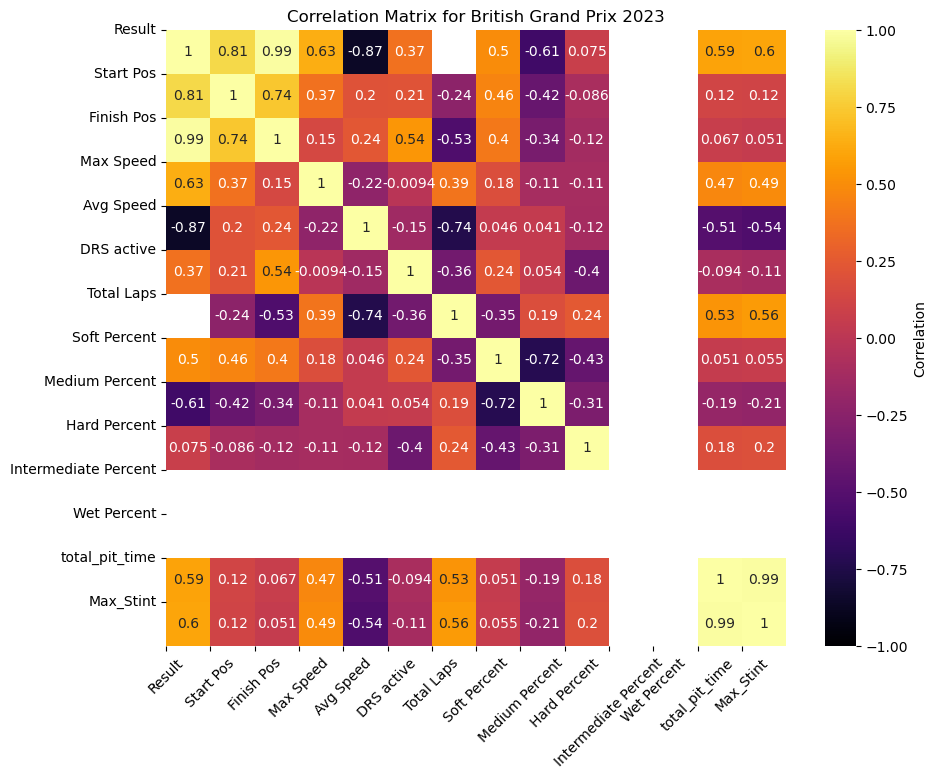

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

#Read in Brittish Grand Prix csv using pandas
BritGP2023 = pd.read_csv("f1 data raw/British Grand Prix 2023.csv")

#Creating Correlation Matrix
corr_matrix = BritGP2023.corr(numeric_only=True)

plt.figure(figsize=(10, 8))

heatmap = sns.heatmap(corr_matrix, cmap='inferno', annot=True, vmin=-1, vmax=1)

# Create colorbar directly from the heatmap object
colorbar = heatmap.collections[0].colorbar
colorbar.set_label('Correlation')

plt.xticks(range(len(corr_matrix)), corr_matrix.columns, rotation=45)
plt.yticks(range(len(corr_matrix)), corr_matrix.columns)

plt.title('Correlation Matrix for British Grand Prix 2023')
plt.show()

## Single Race - Linear Strength

Using the ols function we ran a linear regression model **Result ~ Start Pos + Avg Speed** for the Grand Prix 2023. Here we found that the linear model had an **R-Squared** value of 0.781, which means that about 78% of the variation int the **Result** variable can be explained by the variation in the **Start Pos** and **Avg Speed** variables. This is not the best R-squared value but it is decent. We noticed that the **P-value** for the **Avg Speed** is pretty small, meaning that there is a strong linear relationship between **Avg Speed** and **Result** time. However, the linear regression shows that the **Start Pos** has a **P-value** of 0.18, which is greater than $\alpha$ =0.05 so there is not a strong linear relationship between **Start Pos** and **Result**.

**(Run the code below.)**

(When you run the code you will notice an error saying that the kurtosistest is only valid for n>= 20, since our data for the British Grand Prix 2023 has 3 rows with NaN values for Result time they are not counted in the linear regression, which means our sample size realistically is closer to 17. Which could mean that we can't trust the results from this linear regression test.)

In [ ]:
import statsmodels.formula.api as sm 
from sklearn import linear_model

#Loop to fix variable names so they pull into the ols function properly
for column in BritGP2023.columns:
    if ' ' in column:
        new_column_name = column.replace(' ', '_')
        BritGP2023.rename(columns={column: new_column_name}, inplace=True)

#Creating and testing a linear regression model based off the variables with the strongest variables to predict Result time.
Result_Time_ols = sm.ols(formula="Result ~ Start_Pos + Avg_Speed", data=BritGP2023).fit()
Result_Time_ols.summary()

A more accurate linear model for the British Grand Prix 2023 race would be to create a model that predicts **Result ~ Avg Speed**.

Here you see that our **R-Squared** decreased slighlty to 0.75, but the **P-value** for **Avg Speed** is now much smaller meaning there is a stronger linear relationship here. This is promising, but we want to look at more data and see if we get something similar showing up.

In [30]:
import statsmodels.formula.api as sm 
from sklearn import linear_model

#Loop to fix variable names so they pull into the ols function properly
for column in BritGP2023.columns:
    if ' ' in column:
        new_column_name = column.replace(' ', '_')
        BritGP2023.rename(columns={column: new_column_name}, inplace=True)

#Creating and testing a linear regression model based for Result ~ Average Speed
Result_Time_ols = sm.ols(formula="Result ~ Avg_Speed", data=BritGP2023).fit()
Result_Time_ols.summary()

C:\Users\lorin\anaconda3\Lib\site-packages\scipy\stats\_stats_py.py:1806: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=17
  warnings.warn("kurtosistest only valid for n>=20 ... continuing "


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Result   R-squared:                       0.750
Model:                            OLS   Adj. R-squared:                  0.733
Method:                 Least Squares   F-statistic:                     44.91
Date:                Fri, 19 Apr 2024   Prob (F-statistic):           7.09e-06
Time:                        08:17:17   Log-Likelihood:                -51.137
No. Observations:                  17   AIC:                             106.3
Df Residuals:                      15   BIC:                             107.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   4840.8362    719.584      6.727      0.000    3307.080    6374.593
Avg_Speed    -22.7825      3.400     -6.702      0.000     -30.028     -15.537
==============================================================================
Omnibus:                        1.802   Durbin-Watson:                   1.374
Prob(Omnibus):                  0.406   Jarque-Bera (JB):                1.392
Skew:                          -0.655   Prob(JB):                        0.499
Kurtosis:                       2.501   Cond. No.                     1.20e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.2e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

## All Races - Correlation

Running a correlation matrix and heat map on the data from **total_races** we find that correlation values have decreased across board from when we were looking at the single race. Specifically our two strongest variables **Start Pos** and **Avg Speed** which had strong correlations before are now very weak when compared to **Result** or **Finish Pos**. 

<img src="allracecormatrix.png" alt="Alt text" width="600" height="600">

<br>
At first we were puzzled as to why these variables that had strong correlations with the one race were now very weak when looking at all the races together. We wondered if the British Grand Prix 2023 was just unique, but after running heatmaps on the correlations for each individual race we found that almost all the races showed strong correlations between **Avg Speed** and **Result** time when we ran the correlation matrix on the individual races. 

If you run a scatter plot matrix for the variables for both the single race **British Grand Prix 2023** and also the **total_races** you can see clearer what is going on with the **Avg Speed** variable.

C:\Users\lorin\anaconda3\Lib\site-packages\pandas\plotting\_matplotlib\misc.py:101: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(boundaries_list[j])
C:\Users\lorin\anaconda3\Lib\site-packages\pandas\plotting\_matplotlib\misc.py:102: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(boundaries_list[i])
C:\Users\lorin\anaconda3\Lib\site-packages\pandas\plotting\_matplotlib\misc.py:92: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(boundaries_list[i])


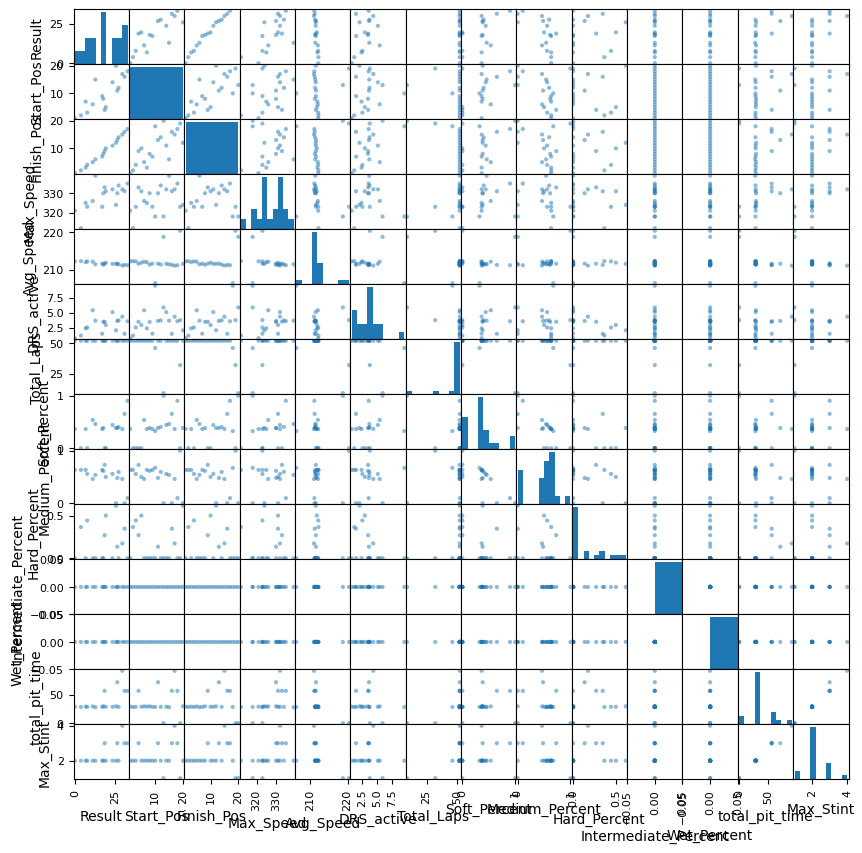

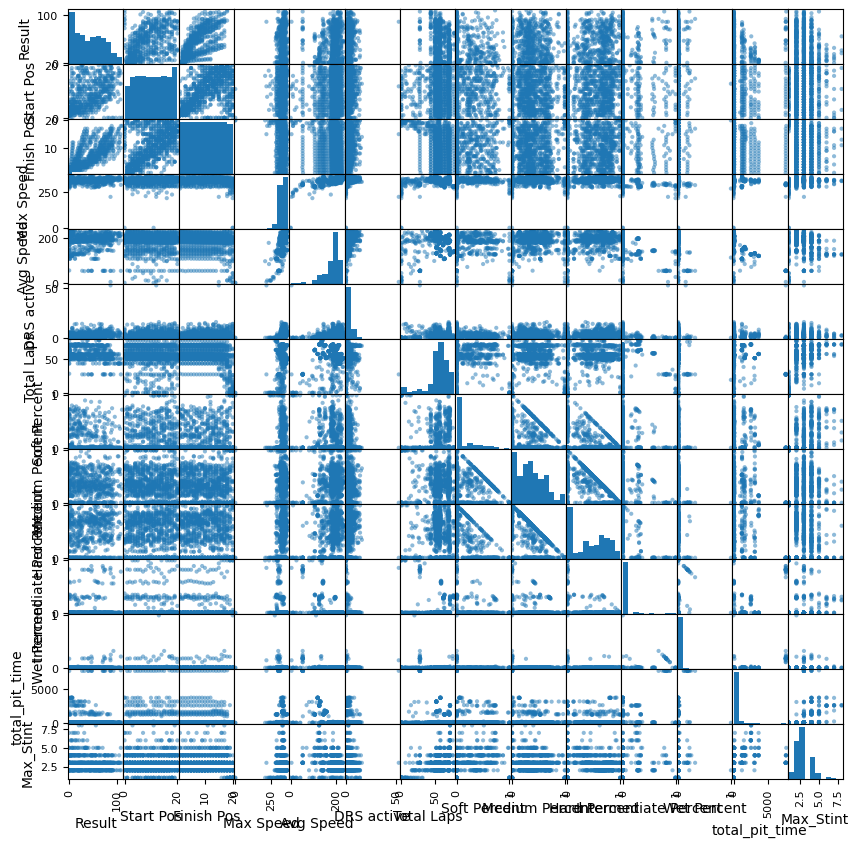

In [31]:
import pandas as pd


pd.plotting.scatter_matrix(BritGP2023, figsize=(10, 10), diagonal='hist');


pd.plotting.scatter_matrix(total_races, figsize=(10, 10), diagonal='hist');


You'll notice that in each race the average speed per driver tends to stay really close to that of the other racers. Which is why the scatter plot of the data appears as a vertical line. When you move to the scatter plot for all the races it appears to be several vertical lines. Because the **Avg Speed** takes on such different quantities from race to race it's difficult to compare the **Avg Speed** between races. Which we believe is what is causing the drop in the correlation value when we move from a single race to all races.

To adjust for the drastic differences in the races themselves we decided it would be better if we normalized the variable **Avg Speed** so that it's values could be compared easily with the other races as well. To do this we decided to use the following code:
<br>
<br>
```python
df['Max Speed'] = (df['Max Speed'] - df['Max Speed'].median()) / max(abs((df['Max Speed'] - df['Max Speed'].median())))
df['Avg Speed'] = (df['Avg Speed'] - df['Avg Speed'].median()) / max(abs((df['Avg Speed'] - df['Avg Speed'].median())))
df['total_pit_time'] = df['total_pit_time'] / df['total_pit_time'].median()
```
<br>

The code calculates the new **Avg Speed** according to the formula:

<br>

$$
\textrm{AVG}_{new} = \frac{\textrm{AVG}- \textrm{AVG}_{median}}{max{\left\lvert \textrm{AVG}- \textrm{AVG}_{median} \right\rvert}}
$$


Essentially turning the Average Speed into a variable measured from -1 to 1 in which it shows how well the variable did compared to the Average Speeds in each race. We felt it was appropriate to scale the average speed down like this because if you look at the shape of the distribution for the **Avg Speed** it keeps the same shape after the normalization just without the skew.



In [1]:
#Creating a data frame including all races where the Max Speed and Average Speed are normalized
import os
import pandas as pd


# Set the folder path
folder_path = "f1 data raw"

# List all files in the folder and filter for CSV files
csv_files = [f for f in os.listdir(folder_path) if f.endswith('.csv')]
csv_list = []

# Iterate through each CSV file
for csv_file in csv_files:
    # Create the full file path
    file_path = os.path.join(folder_path, csv_file)
    
    # Read the CSV file using pandas
    df = pd.read_csv(file_path)
    df = df.dropna(subset=['Result'])
    df['Max Speed'] = (df['Max Speed'] - df['Max Speed'].median()) / max(abs((df['Max Speed'] - df['Max Speed'].median())))
    df['Avg Speed'] = (df['Avg Speed'] - df['Avg Speed'].median()) / max(abs((df['Avg Speed'] - df['Avg Speed'].median())))
    df['total_pit_time'] = df['total_pit_time'] / df['total_pit_time'].median()
    csv_list.append(df)
    
    # Process the DataFrame as needed
    master_driver = pd.concat(csv_list)
master_driver

,Driver,Team,Result,Start Pos,Finish Pos,Max Speed,Avg Speed,DRS active,Total Laps,Soft Percent,Medium Percent,Hard Percent,Intermediate Percent,Wet Percent,total_pit_time,Max_Stint
0,VER,Red Bull Racing,0.000,1.0,1.0,-0.500000,1.000000,0.282535,58,0.000000,0.344828,0.655172,0.0,0.0,0.522414,2.0
1,LEC,Ferrari,8.771,3.0,2.0,-0.375000,0.962525,0.616575,58,0.000000,0.362069,0.637931,0.0,0.0,0.511190,2.0
2,PER,Red Bull Racing,10.093,2.0,3.0,1.000000,0.910900,1.709466,58,0.000000,0.258621,0.741379,0.0,0.0,0.984360,3.0
3,SAI,Ferrari,24.892,4.0,4.0,0.000000,0.642477,2.254909,58,0.000000,0.293103,0.706897,0.0,0.0,1.000000,3.0
4,RUS,Mercedes,35.888,6.0,5.0,0.250000,0.507406,2.786885,58,0.000000,0.586207,0.413793,0.0,0.0,1.197162,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7,TSU,AlphaTauri,74.385,11.0,8.0,-0.161290,-0.381763,0.478044,56,0.035714,0.660714,0.303571,0.0,0.0,1.476448,4.0
8,ALB,Williams,86.714,15.0,9.0,0.161290,-0.742333,1.500512,56,0.000000,0.660714,0.339286,0.0,0.0,1.000308,3.0
9,SAR,Williams,87.998,16.0,10.0,-0.032258,-1.000000,3.497854,56,0.000000,0.625000,0.375000,0.0,0.0,1.037814,3.0
10,HUL,Haas F1 Team,89.904,0.0,11.0,0.032258,-0.495072,2.479564,56,0.000000,0.660714,0.339286,0.0,0.0,1.046775,3.0


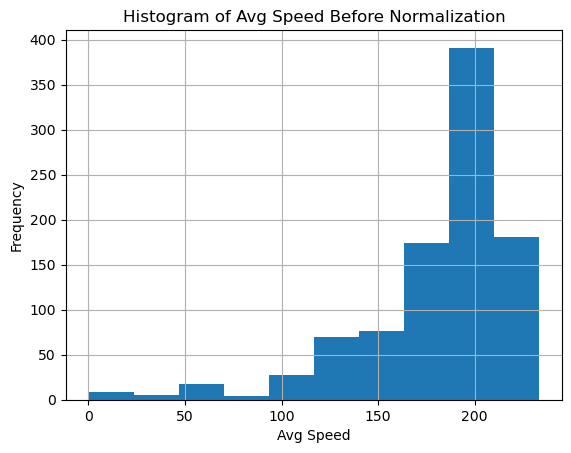

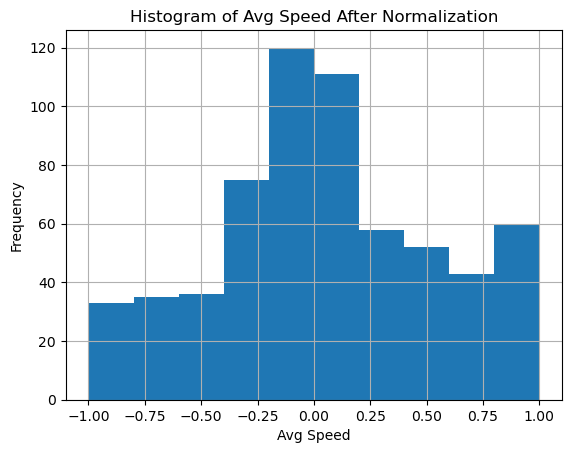

In [33]:
import pandas as pd
import matplotlib.pyplot as plt


#Creating a histogram for Average Speed before normalizing the variable.
total_races['Avg Speed'].hist()

# Add labels and title
plt.xlabel('Avg Speed')
plt.ylabel('Frequency')
plt.title('Histogram of Avg Speed Before Normalization')

# Show the plot
plt.show()


#Creating a histogram for Average Speed after normalizing the variable.
master_driver['Avg Speed'].hist()

# Add labels and title
plt.xlabel('Avg Speed')
plt.ylabel('Frequency')
plt.title('Histogram of Avg Speed After Normalization')

# Show the plot
plt.show()

Running the correlation matrix on the total races after normalizing the **Avg Speed** variable we now start to see the strong correlation we saw when we were working on the individual races.

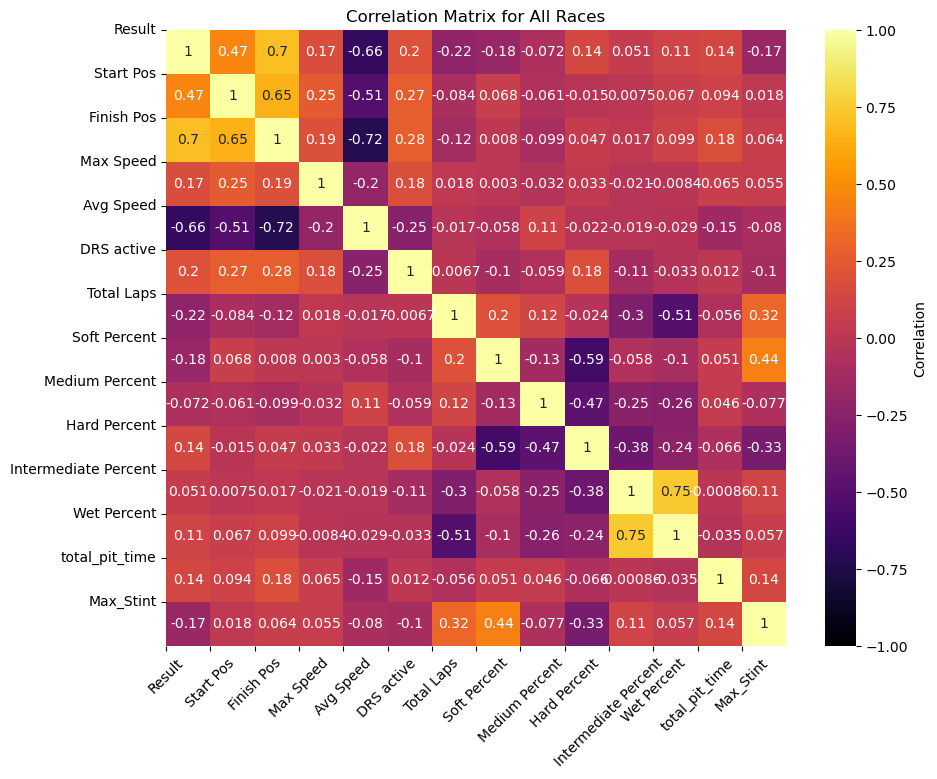

In [34]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

#Creating Correlation Matrix
corr_matrix = master_driver.corr(numeric_only=True)

plt.figure(figsize=(10, 8))

heatmap = sns.heatmap(corr_matrix, cmap='inferno', annot=True, vmin=-1, vmax=1)

# Create colorbar directly from the heatmap object
colorbar = heatmap.collections[0].colorbar
colorbar.set_label('Correlation')

plt.xticks(range(len(corr_matrix)), corr_matrix.columns, rotation=45)
plt.yticks(range(len(corr_matrix)), corr_matrix.columns)

plt.title('Correlation Matrix for All Races')
plt.show()

## All Races - Linear Strength

Using the ols function we ran a linear regression models for both **Result ~ Start Pos + Avg Speed** and **Start Pos ~ Start Pos + Avg Speed** for all the races. 

For the **Result ~ Start Pos + Avg Speed** we found that the linear model had an **R-Squared** value of 0.461, which means that about 46% of the variation in the **Result** time variable can be explained by the variation in the **Start Pos** and **Avg Speed** variables. This is not a very good R-squared value. 

For the **Finish Pos ~ Start Pos + Avg Speed** we found that the linear model had an **R-Squared** value of 0.634, which means that about 63% of the variation in the **Finish Pos** variable can be explained by the variation in the **Start Pos** and **Avg Speed** variables. Although still not the best this is much stronger correlation than the first model. 

In both models we noticed that the **P-value** for both the **Avg Speed** and **Start_Pos** are both essentially zero meaning there is a strong linear relationship between these variables and the **Result** time or **Finish Pos**. However because of the really low R-squared value we would probably not use this linear regretion model to help predict the outcome of the races or whether or not a driver is going to win the race.

**(Run the code below.)**

In [5]:
import statsmodels.formula.api as sm 
from sklearn import linear_model

#Regression model for Result Time ~ Starting Position + Average Speed

#Loop to fix variable names so they pull into the ols function properly
for column in master_driver.columns:
    if ' ' in column:
        new_column_name = column.replace(' ', '_')
        master_driver.rename(columns={column: new_column_name}, inplace=True)

#Creating and testing a linear regression model based off the variables with the strongest variables to predict Result time.
Result_Time_ols = sm.ols(formula="Result ~ Start_Pos + Avg_Speed", data=master_driver).fit()
Result_Time_ols.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Result   R-squared:                       0.461
Model:                            OLS   Adj. R-squared:                  0.459
Method:                 Least Squares   F-statistic:                     265.4
Date:                Fri, 19 Apr 2024   Prob (F-statistic):           5.50e-84
Time:                        09:19:18   Log-Likelihood:                -2813.2
No. Observations:                 623   AIC:                             5632.
Df Residuals:                     620   BIC:                             5646.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     35.8463      1.887     18.998      0.000      32.141      39.552
Start_Pos      0.9577      0.187      5.115      0.000       0.590       1.325
Avg_Speed    -34.2265      2.048    -16.714      0.000     -38.248     -30.205
==============================================================================
Omnibus:                        1.727   Durbin-Watson:                   0.482
Prob(Omnibus):                  0.422   Jarque-Bera (JB):                1.568
Skew:                          -0.073   Prob(JB):                        0.457
Kurtosis:                       3.198   Cond. No.                         27.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [4]:
import statsmodels.formula.api as sm 
from sklearn import linear_model

#Regression model for Finishing Position ~ Starting Position + Average Speed

#Loop to fix variable names so they pull into the ols function properly
for column in master_driver.columns:
    if ' ' in column:
        new_column_name = column.replace(' ', '_')
        master_driver.rename(columns={column: new_column_name}, inplace=True)

#Creating and testing a linear regression model based off the variables with the strongest variables to predict Result time.
Result_Time_ols = sm.ols(formula="Finish_Pos ~ Start_Pos + Avg_Speed", data=master_driver).fit()
Result_Time_ols.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             Finish_Pos   R-squared:                       0.634
Model:                            OLS   Adj. R-squared:                  0.632
Method:                 Least Squares   F-statistic:                     536.2
Date:                Fri, 19 Apr 2024   Prob (F-statistic):          6.38e-136
Time:                        09:18:58   Log-Likelihood:                -1497.8
No. Observations:                 623   AIC:                             3002.
Df Residuals:                     620   BIC:                             3015.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      5.0243      0.228     21.994      0.000       4.576       5.473
Start_Pos      0.3088      0.023     13.624      0.000       0.264       0.353
Avg_Speed     -4.6283      0.248    -18.669      0.000      -5.115      -4.141
==============================================================================
Omnibus:                       38.771   Durbin-Watson:                   1.012
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               52.812
Skew:                           0.517   Prob(JB):                     3.40e-12
Kurtosis:                       3.982   Cond. No.                         27.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

# Analyzing Red Bull's Performance

Now that we know the two variables that have the greatest affect on a racer's time let's look at a couple scatter plots showing the relationship between Result Time ~ Average Speed as well as Result Time ~ Starting Postion. In the scatter plot we've highlighted the **Red Bull Racing Team** in red so you can see their data points. You'll notice how majority of the Red Bull team's data points tend to have really high Average Speeds witch correlate with them having really small Result Times. Also you'll notice that Red Bull Team has data points that tend to have Starting Positions usually between 1-5 which correlate to smaller Race Times. This could be partially why Red Bull is doing well in the races.

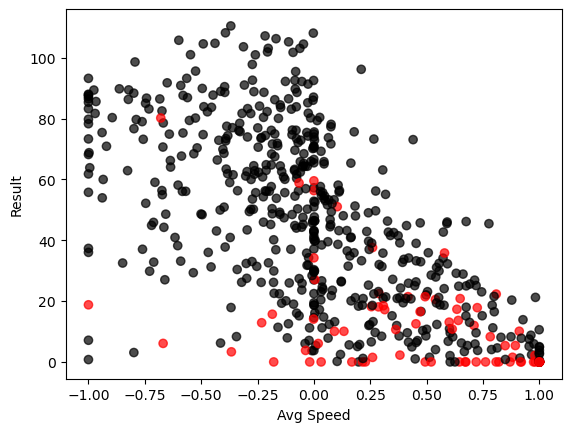

In [37]:
import matplotlib.pyplot as plt
import numpy as np

# Scatter plot showing Result Time ~ Average Speed with Red Bull Racing team highlighted with red dots
colors = np.where(master_driver['Team'] == 'Red Bull Racing', 'red', 'black')

# Adjust the alpha (transparency) of the points
plt.scatter(master_driver['Avg_Speed'], master_driver['Result'], c=colors, alpha=0.7)

plt.xlabel('Avg Speed')
plt.ylabel('Result')
plt.show()

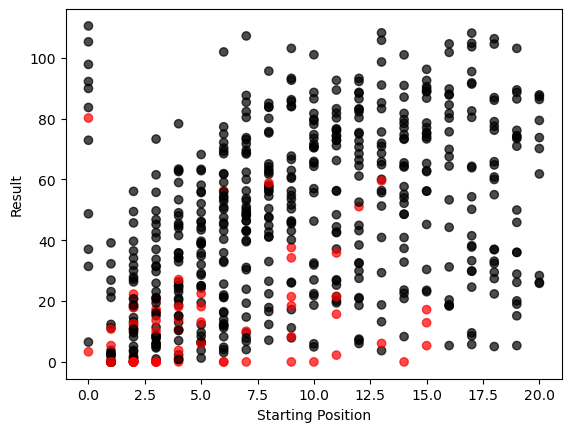

In [38]:
import matplotlib.pyplot as plt

# Scatter plot showing Result Time ~ Starting Position with Red Bull Racing team highlighted with red dots
colors = np.where(master_driver['Team'] == 'Red Bull Racing', 'red', 'black')

# Adjust the alpha (transparency) of the points
plt.scatter(master_driver['Start_Pos'], master_driver['Result'], c=colors, alpha=0.7)

plt.xlabel('Starting Position')
plt.ylabel('Result')
plt.show()

# Preparing the Data for Machine Learning Models

To prepare for ML models, we decided to modify the data less. First we imported the data again; but this time, we did not normalize the Avg Speed, Max Speed, and total_pit_time. We added the race name using the csv name and turned that into a new data frame.

In [8]:
#alternate file retrieval for more information
folder_path = 'f1 data raw/'

csv_files = [f for f in os.listdir(folder_path) if f.endswith('.csv')]
csv_list = []

for csv_file in csv_files:
    file_path = os.path.join(folder_path, csv_file)
    
    track = csv_file[:-9]
    df = pd.read_csv(file_path)
    df = df.dropna(subset=['Result'])
    df['Track'] = track
    csv_list.append(df)
    
    # vectorizes Driver and Track data
    master_driver = pd.concat(csv_list, ignore_index = True)

Additionally, we wanted to be able to have track and driver data be factors in training our models. To do this, we vectorized these columns using the one-hot encoding method, implemented with sklearn. This turns each unique string into its own column containing a boolean of whether that row contains said string. We used this method because it treats each factor as equal weight, and does not assign any order to them.

In [9]:
#vectorizes Driver and Track information
ohe = OneHotEncoder()
ohe_array = ohe.fit_transform(master_driver[['Driver', 'Track']]).toarray()
column_names = ohe.get_feature_names_out(['Driver', 'Track'])
ohe_df = pd.DataFrame(ohe_array, columns= column_names)
ohe_df

,Driver_ALB,Driver_ALO,Driver_BEA,Driver_BOT,Driver_DEV,Driver_GAS,Driver_HAM,Driver_HUL,Driver_LAT,Driver_LAW,...,Track_Las Vegas Grand Prix,Track_Mexico City Grand Prix,Track_Miami Grand Prix,Track_Monaco Grand Prix,Track_Qatar Grand Prix,Track_Sao Paulo Grand Prix,Track_Saudi Arabian Grand Prix,Track_Singapore Grand Prix,Track_Spanish Grand Prix,Track_United States Grand Prix
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
618,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
619,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
620,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
621,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


We then concatenatde this to the master_driver data frame and dropped the columns that would not be used as factors. Finally, we split the data into a training set and test set, and scaled the x data for both sets using StandardScaler().

In [11]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split


#fitting for models
x = pd.concat([master_driver.drop(columns=['Driver','Track', 'Team', 'Result', 'Finish Pos']), ohe_df], axis = 1)
y = master_driver['Finish Pos']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=.2, random_state = 2)

scaler = StandardScaler()
scaler.fit(x_train)

x_train = scaler.transform(x_train)
x_test = scaler.transform(x_test)

# Linear Regression Model
From this dataset, we ran a linear regression model, which performed decently well.

In [13]:
from sklearn.linear_model import LinearRegression


#linear regression model
lin_reg = LinearRegression()
print(lin_reg.get_params())

lin_reg.fit(x_train, y_train)
print(lin_reg.intercept_)
print(lin_reg.coef_)

print(lin_reg.score(x_test,y_test))

{'copy_X': True, 'fit_intercept': True, 'n_jobs': None, 'positive': False}
7.587722874179144
[ 9.47017270e-01  7.08712170e-01 -1.82111434e+00  4.92211646e-01
 -1.26553950e+00 -1.15884474e+12 -1.15394968e+12 -1.60381125e+12
 -8.57399998e+11 -1.53501859e+11 -3.20858765e+00  1.40191650e+00
 -3.93735333e+12 -4.44169655e+12 -8.22977178e+11 -3.43136146e+12
 -1.42256731e+12 -4.23484522e+12 -4.44169655e+12 -2.70190715e+12
 -2.16420982e+12 -8.22977178e+11 -4.01430321e+12 -2.93124516e+12
 -2.00570831e+12 -4.69931022e+12 -3.77767345e+12 -4.76082081e+12
 -3.24185143e+12 -3.14216359e+12 -4.57291411e+12 -4.50793396e+12
 -2.00570831e+12 -4.23484522e+12 -3.03875927e+12 -4.37414476e+12
 -2.70190715e+12 -3.69469365e+12  1.16153953e+12  1.29601102e+12
  8.13362407e+11  1.13720324e+12  1.29601102e+12  1.20843654e+12
  1.18527211e+12  1.18527211e+12  1.20843654e+12  6.03783790e+11
  7.76306431e+11  9.45893993e+11  1.11222361e+12  1.33709591e+12
  9.75903292e+11  1.00489404e+12  1.11222361e+12  1.03295201e+

# MLP Regression Model

Next, we tried a MLP neural network. We ran it with multiple different configurations of the hidden layers. We ran each configuration 5 times and took the average of the test accuracy scores. These were the final results. ![image.png](download.png) With the conditions, we found that hidden_layers = (48, 24) produced the best average results. However, it still only reached .5, which is not great. This is in large part due to the size of our data; it is only 623 rows, making it extremely small compared to the 63 inputs. <br>
We used two layers because it seemed to decrease variance of the scores over one layer, while marginally helping increase the score itself. While this can lead to overfitting with such a small data set, our model doesn't need to be very generalized, as racers and tracks do not change much, often seeing 

# Support Vector Machines

Another model we implemented to predict a racer's performance was Support Vector Machines (SVM). We decided to normalize the max speed and average speed variables so that they were more comparable between races.

Initially, we considered using an SVM regressor, rather than a classifier. What we found, however, was that classifiers were typically around 10% more accurate when working with this dataset. In order to even use a classifier, however, we had to change the predicted variable from result finishing time to final placement. This allowed the predicted variable to be discrete, rather than continuous. 

While using the classifier model, we were also able to drastically increase the efficacy of the model by reducing the possible number of predicted states. By making the classifier predict whether a racer would place on the podium, rather than predict the racer's final placement, the model's accuracy increased by about 70%. Before this jump in accuracy, we were considering only mentioning SVM as an ineffective model for predicting a racer's performance, but afterwards realized that it actually could be used to predict whether a racer would place in the top 3.

The libraries we used for the SVM model are seen here:
```python
from sklearn import tree, svm, metrics
from sklearn.model_selection import train_test_split, cross_val_score, LeaveOneOut
from sklearn.preprocessing import scale
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder
import os
```

We then create a binary classifier:
```python
master_driver['Finish Pos'] = master_driver['Finish Pos'] <= 3
```

The predictors and labels are then chosen from the dataframe:
```python
X = pd.concat([master_driver.drop(columns=['Driver','Track', 'Team', 'Result', 'Finish Pos']), ohe_df], axis = 1) #predictors
y = master['Finish Pos']    #labels
```

We then run through a range of 100 'C' parameters to find the optimal one for this dataset based on its cross-validation score and plot each 'C' parameter's accuracy:
```python
Cs = range(1,100)
Accuracies = np.zeros(len(Cs))
for i,C in enumerate(Cs):
    svm_classifier = svm.SVC(kernel='rbf', C = C,gamma='auto')
    scores = cross_val_score(estimator = svm_classifier, X = scale(X), y = y, cv = 3, scoring='accuracy')
    Accuracies[i]  = scores.mean()

plt.plot(Cs[0:100],Accuracies[0:100])
plt.show()
```

Finally, we print the maximum accuracy the SVM classifier was able to achieve throughout all 100 C values and cross-validation tests:
```python
print("The max accuracy is " + str(max(Accuracies)))
```
<img src="svmstrength.png" alt="Alt text" width="500" height="500">

The maximum accuracy this model was able to achieve was 85.4%. This led us to conclude that an SVM model can be used to effectively predict whether a racer will place on the podium or not, and that this would be the best usage for an SVM model when working with this dataset. This sort of binary classification model was far more accurate than either a discrete prediction model or a continuous regression model.

# Project Summary

From the results from our tests we've determined that the variables that have the greatest impact on **Result** time and **Finish Pos** are **Avg Speed** and **Start Pos**.
We've determined that linear models were a mediocore fit of the data and it turns out that a SVM machine learning model did the best at classifying the final race positions.

We had a lot of fun exploring the data involved in the Formula 1 racing. Looking at the data available and variables that go into every race helped us understand the race in a bigger picture. From our findings the majority of the variables such as number of **Stints**, **Total Pit Time**, **Tire Compound**, etc. had little effect on determining the final winners of the race. The variables that were the best predictors as far as determining who would win the race turned out to be the individual **Starting Position** and **Average Speed** of each racer.

We looked briefly at the data points for the **Red Bull Racing** team and saw how their frequently low starting positions, as well as large average speeds, helped make them top contenders in the races and were most likely a big contributor to the races they've won.

As far as using the information we've learned from this project to help predict future races, the average speed of a racer could be gathered over the qualifiying session and used as an estimate of race speed. Additionally, the Starting Positions of the race are determined by the qualifying races that occur in the days leading up to the final race. Knowing a racer's starting position in the final race could definitely help you predict whether or not they will end up on the podium (the top three winners). This means that if a racing team is trying to decide if they should save their best sets of tires for the final race, it might actually be worth spending the effort, tires, and resources on the qualifying races to ensure a lower placement in starting position for the final race.